# Concavity Violations in Cubic Consumption Functions

With `CubicBool=True`, HARK builds the consumption function by cubic Hermite interpolation through the endogenous gridpoints, using the exact marginal propensity to consume (MPC) at each one. The model's exact consumption function is concave, so its MPC never rises with wealth. A plain cubic through the gridpoints need not be concave, though: on a fine grid, the MPC of HARK's cubic rises on some segments above the borrowing constraint's kink.

This notebook shows where that happens, and two changes that remove it:

- the **shape-preserving cubic**, `ShapePreservingCubicInterp`, which `CubicBool=True` now builds in `IndShockConsumerType`'s solver. It is HARK's cubic Hermite interpolant, with Delbourgo and Gregory's (1985) rational tension added only on the segments whose data would otherwise lose concavity;
- the **continuous expectation**, `IncShkExpectation="continuous"`, which integrates over the income shocks' continuous distributions instead of summing over their discrete atoms.

The page [Concavity Violations in Cubic Consumption Functions](https://econ-ark.github.io/HARK-dev/concavity-violations/) explains the mechanism in full. This notebook regenerates its key results with HARK's own code, at HARK's default parameters.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from HARK.ConsumptionSaving.ConsIndShockModel import (
    IndShockConsumerType,
    get_mNrm_kinks,
)
from HARK.interpolation import CubicHermiteInterp

## Measuring concavity violations

A concave consumption function has an MPC that never rises with wealth. The function below takes the cubic part of a solved consumption function and checks each segment between gridpoints above the borrowing constraint's kink. It reports how many segments have a rising MPC, and the largest rise.

It can also take a plain cubic Hermite interpolant through the same gridpoints, levels and MPCs (`plain=True`). That isolates the interpolant: both functions pass through the same data, and only the curve between the gridpoints differs.

In [2]:
def cubic_part(solution, plain=False):
    # The consumption function is the lower envelope of a cubic and the constraint
    cubic = solution.cFunc.functions[0]
    if plain:
        cubic = CubicHermiteInterp(cubic.x_list, cubic.y_list, cubic.dydx_list)
    return cubic


def concavity_violations(solution, plain=False, points_per_segment=50):
    cubic = cubic_part(solution, plain)
    kink = get_mNrm_kinks(solution)[0]
    knots = solution.cFunc.functions[0].x_list
    count, largest = 0, 0.0
    for lo, hi in zip(knots[:-1], knots[1:]):
        if hi <= kink:
            continue
        m = np.linspace(max(lo, kink), hi, points_per_segment)
        mpc = cubic.derivative(m)
        rise = np.max(np.maximum.accumulate(mpc[::-1])[::-1] - mpc)
        if rise > 1e-12:
            count += 1
            largest = max(largest, rise)
    return count, largest


def tensed_segments(solution):
    return int(np.sum(solution.cFunc.functions[0].tension > 0.0))

## HARK's cubic over discrete atoms

The default `IndShockConsumerType` takes the expectation over its income shocks as a sum over discrete atoms, seven equiprobable points per shock plus the unemployment event. Each atom sends next period's borrowing-constraint kink back to one point of this period's consumption function, the kink's image under that atom, where the exact solution then has a kink of its own. A cubic segment that holds one of these points cannot follow the kink, and its MPC rises on part of the segment. On a coarse grid the segments are wide and the cubic happens to stay concave; on finer grids it does not, and refining the grid does not remove the violations: the finer the grid, the more segments violate concavity.

Below, the model is solved on three grids. For each grid, the table counts the segments that violate concavity under a plain cubic through the solution's gridpoints and under the shape-preserving cubic that `CubicBool=True` builds.

In [3]:
grids = [48, 200, 500]
atoms = {}
for count in grids:
    agent = IndShockConsumerType(cycles=0, CubicBool=True, aXtraCount=count)
    agent.solve()
    atoms[count] = agent.solution[0]

print(
    "gridpoints   plain cubic: segments, largest MPC rise   shape-preserving: segments   tensed"
)
for count, solution in atoms.items():
    n, rise = concavity_violations(solution, plain=True)
    n_sp, _ = concavity_violations(solution)
    print(
        f"{count:10d}   {n:21d}, {rise:.1e}   {n_sp:28d}   {tensed_segments(solution):6d}"
    )

gridpoints   plain cubic: segments, largest MPC rise   shape-preserving: segments   tensed
        48                       0, 0.0e+00                              0        0
       200                       2, 3.4e-04                              0        2
       500                       4, 1.9e-04                              0        4


On the finest grid, the MPC of the plain cubic rises on a few segments above the kink, while the shape-preserving cubic's never does. The figure shows the two MPCs there.

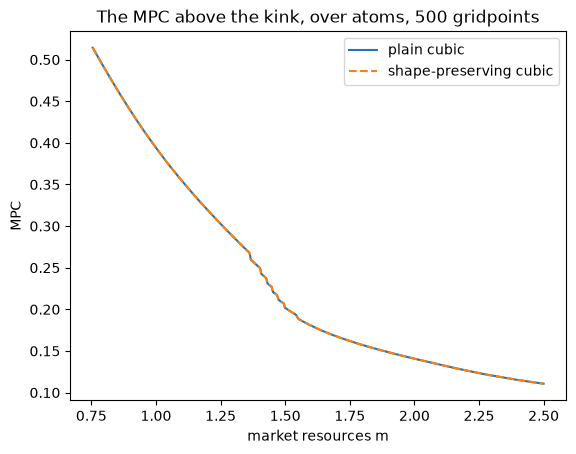

In [4]:
solution = atoms[500]
kink = get_mNrm_kinks(solution)[0]
m = np.linspace(kink, 2.5, 20001)
plt.plot(m, cubic_part(solution, plain=True).derivative(m), label="plain cubic")
plt.plot(m, cubic_part(solution).derivative(m), "--", label="shape-preserving cubic")
plt.xlabel("market resources m")
plt.ylabel("MPC")
plt.title("The MPC above the kink, over atoms, 500 gridpoints")
plt.legend()
plt.show()

## The continuous expectation

Integrating against the shocks' continuous distributions removes the atoms' images: next period's kink then leaves no kink in this period's consumption function, and the cubic has nothing it cannot follow. With `IncShkExpectation="continuous"`, the solver takes the expectation by Gauss–Legendre quadrature in pieces, cut at each unit step of the shocks' standard-normal coordinates and wherever next period's cash-on-hand reaches its kink or a knot of its consumption function, so that the integrand is smooth on each piece. The companion page [Kink-Split Quadrature](https://econ-ark.github.io/HARK-dev/kink-split-quadrature/) explains the method.

The continuous expectation needs the distributions themselves, which the income constructor records. Here both shocks are lognormals truncated at three standard deviations of the underlying normal, with mean one and the stated standard deviation of the log kept (`PermShk_inf`, `PermShk_sup`, `TranShk_inf`, `TranShk_sup`).

In [5]:
bounds = {
    "PermShk_inf": -3.0,
    "PermShk_sup": 3.0,
    "TranShk_inf": -3.0,
    "TranShk_sup": 3.0,
}

continuous_grids = [48, 200]
continuous = {}
for count in continuous_grids:
    agent = IndShockConsumerType(
        cycles=0,
        CubicBool=True,
        aXtraCount=count,
        IncShkExpectation="continuous",
        **bounds,
    )
    agent.solve()
    continuous[count] = agent.solution[0]

print("gridpoints   plain cubic: segments, largest MPC rise   tensed")
for count, solution in continuous.items():
    n, rise = concavity_violations(solution, plain=True)
    print(f"{count:10d}   {n:21d}, {rise:.1e}   {tensed_segments(solution):6d}")

gridpoints   plain cubic: segments, largest MPC rise   tensed
        48                       0, 0.0e+00        0
       200                       0, 0.0e+00        0


Even the plain cubic through these gridpoints is concave, on both grids, and the shape-preserving cubic adds no tension anywhere.

## The atoms' error

Atoms also make an error of their own: they replace the shocks' distributions by a few points, and refining the asset grid does not remove that error. The comparison below solves the same model, with the same truncated distributions, over seven atoms per shock, and measures the largest difference in consumption from the continuous solution on each grid.

In [6]:
m = np.linspace(0.0, 20.0, 2001)
print("gridpoints   max |c(atoms) - c(continuous)|")
for count in continuous_grids:
    agent = IndShockConsumerType(cycles=0, CubicBool=True, aXtraCount=count, **bounds)
    agent.solve()
    gap = np.max(np.abs(agent.solution[0].cFunc(m) - continuous[count].cFunc(m)))
    print(f"{count:10d}   {gap:.1e}")

gridpoints   max |c(atoms) - c(continuous)|
        48   1.4e-02
       200   1.4e-02


The gap stays near 1e-2 on both grids: it is the atoms', not the grid's.

## Nodes a piece

The continuous expectation's accuracy is set by the grid and by the number of Gauss–Legendre nodes in each piece of the integral: `PermShkQuadCount` for the permanent shock and `TranShkQuadCount` for the transitory one, 4 each by default. On the default grid, the table compares solutions at two to four nodes a piece with one at eight.

In [7]:
def solve_continuous(perm_nodes, tran_nodes):
    agent = IndShockConsumerType(
        cycles=0,
        CubicBool=True,
        IncShkExpectation="continuous",
        PermShkQuadCount=perm_nodes,
        TranShkQuadCount=tran_nodes,
        **bounds,
    )
    agent.solve()
    return agent.solution[0].cFunc


reference = solve_continuous(8, 8)
print("nodes (permanent, transitory)   max |c - c(8, 8)|")
for nodes in [(2, 2), (3, 3), (4, 4)]:
    gap = np.max(np.abs(solve_continuous(*nodes)(m) - reference(m)))
    print(f"{str(nodes):30s}   {gap:.1e}")

nodes (permanent, transitory)   max |c - c(8, 8)|
(2, 2)                           1.3e-03
(3, 3)                           8.5e-06
(4, 4)                           6.3e-08


Each piece spans at most one unit step of a shock's standard-normal coordinate, and no knot of next period's consumption function falls inside one, so the integrand is smooth on every piece and the error falls geometrically in the nodes, by about two orders of magnitude for each node more. The default, four nodes a piece, is accurate to about 6e-8 here.